# Subquestion 1: ranking by crashes vs. ranking by crash rate

In [4]:
import pandas as pd

df = pd.read_csv("cleaned_data/05_analysis_ready_zh_motorways.csv")
print(df.shape)
df.head()

(1228, 28)


,VBN_ID,ROAD_DESCRIPTION,ROAD_NUMBER,ROAD_LENGTH_M,DIRECTION_BEGIN,DIRECTION_END,CARRIAGEWAY_TYPE_BEGIN,CARRIAGEWAY_TYPE_END,HAS_TRAFFIC_DATA,AVG_DAILY_TRAFFIC,...,TRAFFIC_COVERAGE_PCT,ANNUAL_VEHICLE_KM,TOTAL_CRASHES,MATERIAL_DAMAGE_CRASHES,INJURY_CRASHES,FATAL_CRASHES,INJURY_FATAL_CRASHES,CRASH_RATE_PER_100M_VKM,INJURY_FATAL_RATE_PER_100M_VKM,GEOMETRY_WKT
0,10000000001492700860,A15 b (OPR) Havens 5500-5600,A15,45.0,Re,Re,OPR,OPR,1,250.0,...,100.0,4106.25,0,0,0,0,0,0.000000,0.0,"LINESTRING (74567.64199 435285.76651, 74568.62..."
1,10000000001512701040,A15 b (OPR) Rozenburg,A15,97.0,Re,Re,OPR,OPR,1,3100.0,...,100.0,109755.50,0,0,0,0,0,0.000000,0.0,"LINESTRING (75525.972 435244.552, 75528.06123 ..."
2,10000000001512701050,A15 d (OPR) ROZENBURG,A15,140.0,Li,Li,OPR,OPR,1,2800.0,...,100.0,143080.00,0,0,0,0,0,0.000000,0.0,"LINESTRING (75723.8393445015 435362.893433999,..."
3,10000000001512810410,A20 b (OPR) Maasdijk-Oost,A20,378.0,Re,Re,OPR,OPR,1,6100.0,...,100.0,841617.00,1,1,0,0,0,118.818893,0.0,"LINESTRING (75556.498 441053.268, 75575.046100..."
4,10000000001512820560,A20 d (OPR) Maasdijk-Oost,A20,377.0,Li,Li,OPR,OPR,1,3900.0,...,100.0,536659.50,0,0,0,0,0,0.000000,0.0,"LINESTRING (75658.233 441162.014, 75654.673099..."


In [2]:
report = pd.read_csv("cleaned_data/00_cleaning_report.csv")
report

,CHECK,VALUE
0,All INWEVA carriageways,8763
1,A-road carriageways,6920
2,Selected South Holland A-road carriageways,1228
3,Boundary-crossing carriageways excluded,19
4,Outside South Holland excluded,5656
5,No usable municipality mapping excluded,17
6,Selected sections with traffic data,1223
7,Directly assigned crashes,7172
8,Uniquely assigned junction crashes,121
9,Ambiguous junction crashes,10


In [5]:
cols = ["ROAD_LENGTH_M", "AVG_DAILY_TRAFFIC", "TOTAL_CRASHES", "CRASH_RATE_PER_100M_VKM"]
df[cols].describe()

,ROAD_LENGTH_M,AVG_DAILY_TRAFFIC,TOTAL_CRASHES,CRASH_RATE_PER_100M_VKM
count,1228.000000,1223.000000,1228.000000,1223.000000
mean,766.064332,22986.950123,5.938925,119.538730
std,915.771545,20538.807408,13.136808,514.709963
min,8.000000,180.000000,0.000000,0.000000
25%,293.750000,6300.000000,0.000000,0.000000
50%,503.000000,15300.000000,1.000000,31.771846
75%,875.250000,36500.000000,5.000000,90.882043
max,9303.000000,99700.000000,159.000000,10537.407798


In [6]:
show = ["ROAD_DESCRIPTION", "ROAD_LENGTH_M", "AVG_DAILY_TRAFFIC", "TOTAL_CRASHES", "CRASH_RATE_PER_100M_VKM"]
df.sort_values("CRASH_RATE_PER_100M_VKM", ascending=False)[show].head(10)

,ROAD_DESCRIPTION,ROAD_LENGTH_M,AVG_DAILY_TRAFFIC,TOTAL_CRASHES,CRASH_RATE_PER_100M_VKM
1089,A12 c (AFR) Nieuwerbrug,26.0,1000.0,1,10537.407798
354,A13 b (OPR) Delft-Noord (wegdeel B),43.0,4800.0,7,9291.706488
427,A20 d (OPR) Kp.kethelplein,11.0,7900.0,2,6305.468417
16,A4 b (OPR) Den Hoorn,334.0,2300.0,10,3566.422842
348,A15 b (OPR) Hoogvliet,22.0,3800.0,1,3277.184243
412,A4 a (AFR) Knooppunt Benelux (wegdeel B),32.0,6100.0,2,2807.096340
561,A15 b (OPR) Rotterdam-Heijplaat,25.0,4000.0,1,2739.726027
1066,A13 c (AFR) Rotterdam-Noordwest (wegdeel B),35.0,3000.0,1,2609.262883
1166,A16 a (AFR) Dordrecht-Centrum,27.0,4400.0,1,2306.166690
204,A15 a (AFR) Havens 5500-5700,514.0,240.0,1,2220.919283


In [11]:
df["CRASH_RATE_PER_M_VKM"] = df["TOTAL_CRASHES"] / df["ANNUAL_VEHICLE_KM"] * 1000000

for thres in [0.5e6, 1e6, 2e6, 5e6]:
    mask = df["ANNUAL_VEHICLE_KM"] >= thres
    print(f"min {thres/1e6:.1f} mln vkm: {mask.sum()} segmenten, "
          f"{df.loc[mask, 'TOTAL_CRASHES'].sum()} van {df['TOTAL_CRASHES'].sum()} ongevallen") #with a threshold of 1 mil, 97% of the accidents are kept. but 400 small or quiet roads are filtered out. 

min 0.5 mln vkm: 979 segmenten, 7213 van 7293 ongevallen
min 1.0 mln vkm: 849 segmenten, 7103 van 7293 ongevallen
min 2.0 mln vkm: 680 segmenten, 6900 van 7293 ongevallen
min 5.0 mln vkm: 473 segmenten, 6531 van 7293 ongevallen


In [20]:
MIN_VKM = 1_000_000   # minimum annual vehicle-km for the rate ranking

eligible = df[df["ANNUAL_VEHICLE_KM"] >= MIN_VKM].copy()

show = ["ROAD_DESCRIPTION", "ROAD_LENGTH_M", "AVG_DAILY_TRAFFIC",
        "TOTAL_CRASHES", "CRASH_RATE_PER_M_VKM"]

top_count = df.sort_values("TOTAL_CRASHES", ascending=False).head(10)
top_rate = eligible.sort_values("CRASH_RATE_PER_M_VKM", ascending=False).head(10)

top_count[show]

,ROAD_DESCRIPTION,ROAD_LENGTH_M,AVG_DAILY_TRAFFIC,TOTAL_CRASHES,CRASH_RATE_PER_M_VKM
795,A16 Li (HR) Knooppunt IJsselmondse Plein - Van...,6296.0,48300.0,159,1.432493
695,A4 Re (HR) Leiden,4807.0,49600.0,156,1.792569
482,A4 Li (HR) Knooppunt Prins Clausplein - Kp.pr....,2371.0,54700.0,107,2.260331
688,A20 Li (HR) KP TERBREGSEPLEIN - Rotterdam-Croo...,2339.0,66200.0,94,1.663209
742,A16 Re (HR) Van Brienenoordbrug - Knooppunt IJ...,5059.0,52700.0,92,0.945409
627,A15 Li (HR) Portlandsebrug,4431.0,45400.0,78,1.062293
544,A4 Li (HR) Kp.pr.clausplein - Leidschendam-Voo...,5894.0,87800.0,76,0.402361
393,A4 Li (HR) Kp.kethelplein - Delft,5381.0,53500.0,75,0.713759
825,A20 Re (HR) Pr.alexander - Nieuwerkerk A/d Ijssel,4033.0,50300.0,74,0.999408
776,A20 Li (HR) Rotterdam-Pr.alexander - KP TERBRE...,1032.0,70800.0,73,2.737266


In [21]:
top_rate[show]

,ROAD_DESCRIPTION,ROAD_LENGTH_M,AVG_DAILY_TRAFFIC,TOTAL_CRASHES,CRASH_RATE_PER_M_VKM
609,A20 a (AFR) Rotterdam-Noord,400.0,7700.0,10,8.895214
57,A4 b (OPR) Vlaardingen-Oost,287.0,10300.0,9,8.341238
87,A20 d (OPR) Rotterdam-Schiebroek,415.0,12200.0,11,5.952397
600,A20 c (AFR) Knooppunt Kleinpolderplein - Kp.kl...,400.0,7000.0,6,5.870841
377,A4 a (AFR) Vlaardingen-Oost,380.0,8500.0,6,5.089274
749,A15 a (AFR) Rotterdam-Ijsselmonde,404.0,14200.0,10,4.775704
1074,A4 c (AFR) Leiden,603.0,6200.0,6,4.396928
179,A15 Re (HR) Rotterdam - oostvoorne,731.0,13700.0,15,4.103557
683,A29 Re (HR) Knooppunt Vaanplein,627.0,7800.0,7,3.921417
91,A20 b (OPR) Rotterdam-Noord,251.0,16800.0,6,3.898301


In [22]:
overlap = set(top_count["VBN_ID"]) & set(top_rate["VBN_ID"])
print("Sections in both top 10s:", len(overlap))

df[df["VBN_ID"].isin(overlap)][show]

Sections in both top 10s: 0


,ROAD_DESCRIPTION,ROAD_LENGTH_M,AVG_DAILY_TRAFFIC,TOTAL_CRASHES,CRASH_RATE_PER_M_VKM


In [24]:
rho = eligible["TOTAL_CRASHES"].corr(eligible["CRASH_RATE_PER_M_VKM"], method="spearman")
print(f"Spearman rank correlation (count vs. rate): {rho:.2f}")

Spearman rank correlation (count vs. rate): 0.71


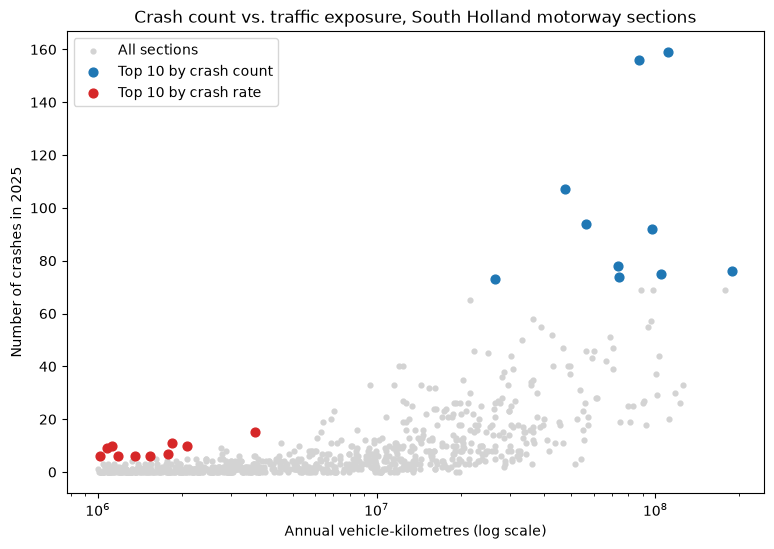

In [25]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(eligible["ANNUAL_VEHICLE_KM"], eligible["TOTAL_CRASHES"],
           s=12, color="lightgrey", label="All sections")
ax.scatter(top_count["ANNUAL_VEHICLE_KM"], top_count["TOTAL_CRASHES"],
           s=40, color="tab:blue", label="Top 10 by crash count")
ax.scatter(top_rate["ANNUAL_VEHICLE_KM"], top_rate["TOTAL_CRASHES"],
           s=40, color="tab:red", label="Top 10 by crash rate")

ax.set_xscale("log")
ax.set_xlabel("Annual vehicle-kilometres (log scale)")
ax.set_ylabel("Number of crashes in 2025")
ax.set_title("Crash count vs. traffic exposure, South Holland motorway sections")
ax.legend()
plt.show()

In [26]:
with_crashes = eligible[eligible["TOTAL_CRASHES"] > 0]
rho2 = with_crashes["TOTAL_CRASHES"].corr(with_crashes["CRASH_RATE_PER_M_VKM"], method="spearman")
print(f"Spearman, only sections with >= 1 crash: {rho2:.2f}")

Spearman, only sections with >= 1 crash: 0.40


In [28]:
with_traffic = df[df["ANNUAL_VEHICLE_KM"] > 0]

by_type = with_traffic.groupby("CARRIAGEWAY_TYPE_BEGIN").agg(
    sections=("VBN_ID", "size"),
    crashes=("TOTAL_CRASHES", "sum"),
    vehicle_km=("ANNUAL_VEHICLE_KM", "sum"),
)
by_type["rate_per_M_vkm"] = by_type["crashes"] / by_type["vehicle_km"] * 1_000_000
by_type.sort_values("rate_per_M_vkm", ascending=False)

,sections,crashes,vehicle_km,rate_per_M_vkm
CARRIAGEWAY_TYPE_BEGIN,,,,
AFR,269,257,2.571857e+08,0.999278
OPR,233,237,2.560156e+08,0.925725
HR,416,6324,9.783961e+09,0.646364
VBI,14,14,2.825297e+07,0.495523
VBS,48,97,2.830386e+08,0.342709
VBR,160,297,8.923044e+08,0.332846
PST,5,9,3.055028e+07,0.294596
VBK,22,22,7.898162e+07,0.278546
VBD,56,35,2.126485e+08,0.164591


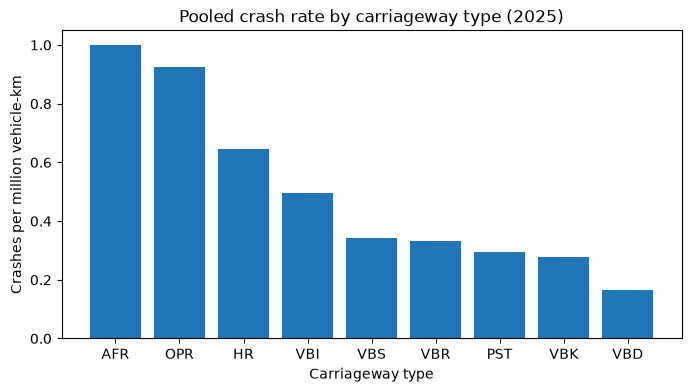

In [29]:
by_type_sorted = by_type.sort_values("rate_per_M_vkm", ascending=False)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(by_type_sorted.index, by_type_sorted["rate_per_M_vkm"], color="tab:blue")
ax.set_xlabel("Carriageway type")
ax.set_ylabel("Crashes per million vehicle-km")
ax.set_title("crash rate by carriageway type (2025)")
plt.show()

## Conclusion sub-question 1

The ranking by crash count and the ranking by crash rate point to different sections:
**none of the top 10 sections appears in both lists.**

- **By crash count**, the top 10 consists entirely of long main carriageways (1–6 km) with very high
  traffic volumes (45,000–88,000 vehicles/day). They have many crashes (73–159), but a relatively low
  crash rate (0.4–2.7 crashes per million vehicle-km): they score high mainly because they are busy and long.
- **By crash rate**, the top 10 consists almost entirely of short on- and off-ramps (250–730 m) with moderate
  traffic (6,000–17,000 vehicles/day), mainly around Rotterdam (A20, A15) and Vlaardingen (A4).
  They have fewer crashes (6–15), but 4–9 crashes per million vehicle-km.

Across all sections, the two rankings are positively related (Spearman ρ = 0.71), but they diverge
completely at the top. When the sections without crashes are filtered out, the correlation drops to p = 0.40, so a lot of overlap is at sections without crashes. 

**Method choice:** Short sections were not removed, so crashes on ramps and merging lanes are included.
To prevent sections with very little traffic from getting extreme rates based on one or two crashes,
only sections with at least 1 million vehicle-km per year are included in the rate ranking
(849 of 1,228 sections, covering 97% of all crashes). With a threshold of 0.5 million vehicle-km the
individual sections change, but the pattern (ramps at the top) remains the same.

**Rates by carriageway type.** To check if the pattern in the top 10 is not just driven by a few
sections with small numbers of crashes, crashes and vehicle-km were summed per carriageway type over all
sections with traffic data. Off-ramps (1.00 crashes per million vehicle-km) and on-ramps (0.93) have a crash
rate about 1.5 times higher than main carriageways (0.65). At the same time, main carriageways account for
87% of all crashes (6,324 of 7,293). So in conclusion, most crashes happen on the main carriageway, but the highest
risk per vehicle-km is found on the ramps.

**Limitation:** The high-rate sections are based on small numbers of crashes, so their exact order is
uncertain. The robust finding is that on- and off-ramps have structurally higher crash rates than
main carriageways.